# The null family: does every test hold its size?

**Question:** Which validation tests reject a correct model more often than their level allows, and what in the construction of each offender explains it?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (size, power and the Monte Carlo error)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- apply the rule that decides whether a test holds its size, the exact probability where one exists and the one-sided bound on a simulated rate where it does not, to every row of the null family;
- name the tests that reject a right model more often than their level allows and tell, for each, which part of its construction is responsible;
- reproduce the Hosmer-Lemeshow degrees-of-freedom effect and the heavy tail of the normal test over five years with the engine, on the generators of the study;
- read the exact size of the traffic-lights test under its two tie rules and of the Jeffreys test over a range of PDs;
- treat the AUC as an estimator and read its bias, its model error and the coverage of its interval.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `null` family of case C22, validating the validator: the same file as notebook 01, now read in full. Each row runs one registered test on datasets drawn by a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`) in which the null hypothesis holds, so every rejection is a false alarm. The family covers the tests of the credit families and the tests the engine added afterwards for exposure, provisions, market risk, portfolio credit, fairness and machine learning.

- **File read:** `data/derived/C22/null.json`, keys `outputs` (rows, generators, levels) and `provenance`.
- **What is taken from it:** the committed counts of every row, to apply the size rule, and the configuration and seed of a few rows, to draw their datasets again here.

The next cell loads the file, lists the null rows and prints the engine version that wrote it beside the installed one.

In [2]:
# Load the null family and index its simulations by key
LANG = "en"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
null_keys = [key for key in rows if key.endswith("@null")]
print("simulations:", len(rows), "| null rows:", len(null_keys))
print("baked by riskvalidation", null["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

simulations: 53 | null rows: 46
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

The size of a test is its rejection probability when the null holds, and the study estimates it as a rate over 4000 repetitions (notebook 01). Two rules turn a rate into a verdict, applied at 5% and at 1%:

- where the exact rejection probability exists, as for the count tests and the traffic lights over independent years, the test holds its size when $P(\text{reject}) \le \alpha$;
- where it does not, the test holds its size when the simulated rate does not exceed $\alpha + 3.09\sqrt{\alpha(1-\alpha)/n}$, the bound that the engine's `within_size` applies.

A test that holds its size at both levels passes. The steps apply the rule to every null row, then open the offenders one by one: for each, a short computation with the engine that reproduces its size from the way the test is built.

### Step 1: the size rule on every null row

For each row ending in `@null` the next cell takes the exact probability when the row has one and otherwise builds a `Rate` from the committed counts and asks `within_size`. It prints how many rows hold at both levels and the rates of those that do not, then draws the 5% rate of every row with its Wilson interval, green when the row holds its size and red when it does not.

tests that hold their size at 5% and 1%: 42 of 46
pd.jeffreys@null                             [0.039, 0.0112]
pd.normal_multiperiod@null                   [0.0838, 0.0405]
market.christoffersen_independence@null      [0.0568, 0.0152]
market.christoffersen_conditional_coverage@null [0.069, 0.0143]


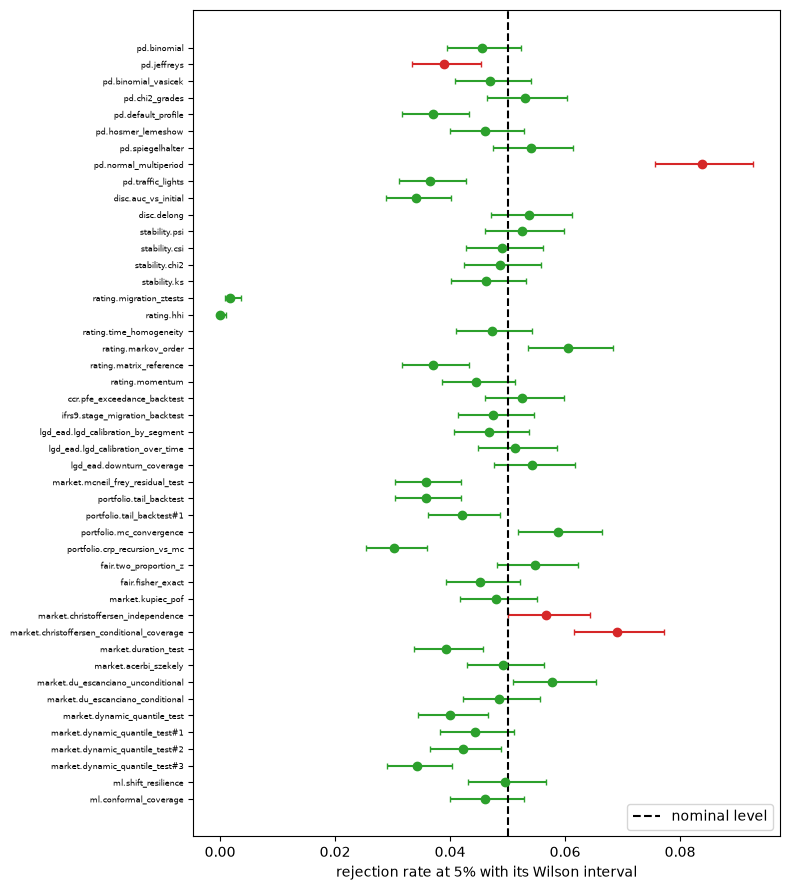

In [3]:
# Apply the engine size rule to every null row and draw the rates with their Wilson intervals
from riskvalidation.harness.rates import Rate, within_size

holds = {}
for key in null_keys:
    verdicts = []
    for alpha in out["levels"]:
        rule = f"p<{alpha:g}"
        exact = (rows[key]["exact"] or {}).get(rule)
        c = rows[key]["rates"][rule]
        rate = Rate(c["rejections"], c["n"])
        verdicts.append(exact <= alpha + 1e-12 if exact is not None else within_size(rate, alpha))
    holds[key] = all(verdicts)
print("tests that hold their size at 5% and 1%:", sum(holds.values()), "of", len(holds))
for key in null_keys:
    if not holds[key]:
        print(f"{key:44s}", [round(rows[key]["rates"][f"p<{a:g}"]["rate"], 4) for a in out["levels"]])
fig, ax = plt.subplots(figsize=(8, 9))
for i, key in enumerate(null_keys):
    c = rows[key]["rates"]["p<0.05"]
    errors = [[c["rate"] - c["wilson_low"]], [c["wilson_high"] - c["rate"]]]
    ax.errorbar(c["rate"], i, xerr=errors, fmt="o", capsize=2, color="tab:green" if holds[key] else "tab:red")
ax.axvline(0.05, color="black", linestyle="--", label="nominal level")
ax.set_yticks(range(len(null_keys)))
ax.set_yticklabels([key[:-5] for key in null_keys], fontsize=6)
ax.invert_yaxis()
ax.set_xlabel("rejection rate at 5% with its Wilson interval")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Forty-two of the 46 null rows hold their size at both levels. The four red rows are the Jeffreys test, the normal test over five years and two Christoffersen tests of value-at-risk exceedances. The normal test is the clear case, with rates of 0.0838 at 5% and 0.0405 at 1%, roughly double the level. The other three are close to the line: their rates, 0.0112, 0.0152 and 0.0690, exceed the allowed bound at a single level by a small amount. Each offender is opened in the next steps.

### Step 2: Hosmer-Lemeshow and its degrees of freedom

The Hosmer-Lemeshow statistic groups obligors into $G$ groups by predicted PD and adds the standardised gaps between observed and expected defaults (Hosmer and Lemeshow, 1980). When the PDs come from a model fitted on the same data, the original reference distribution is $\chi^2_{G-2}$; when the PDs are given, as in a validation, each group's gap is asymptotically normal and the reference is $\chi^2_{G}$. The engine's `pd_hosmer_lemeshow` takes a `fitted` flag. The next cell runs the test through `simulate` on the logistic generator of the study, a right model of 5,000 obligors, once with each reference, and draws the p-values: under an exact test they are flat.

G degrees of freedom     | 5%: 0.0475 | 1%: 0.0125
G-2 degrees of freedom   | 5%: 0.1150 | 1%: 0.0300


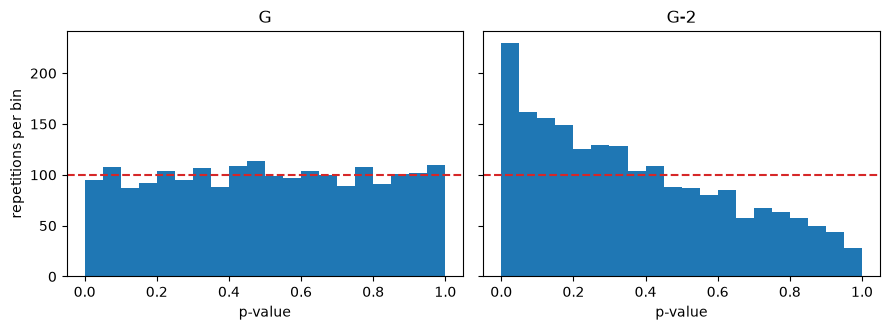

In [4]:
# Run the Hosmer-Lemeshow test with G and with G-2 degrees of freedom on a right logistic model
from riskvalidation.generators.scores import LogisticPortfolio
from riskvalidation.harness.run import simulate

spec = out["generators"]["logistic-5000"]
logit = LogisticPortfolio(**spec["config"])
seed = rows["pd.hosmer_lemeshow@null"]["seed"]
given = simulate("pd.hosmer_lemeshow", logit, n_rep=2000, seed=seed)
fitted = simulate("pd.hosmer_lemeshow", logit, n_rep=2000, seed=seed, test_kwargs={"fitted": True})
for name, run in (("G degrees of freedom", given), ("G-2 degrees of freedom", fitted)):
    print(f"{name:24s} | 5%: {run.rates['p<0.05'].rate:.4f} | 1%: {run.rates['p<0.01'].rate:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, run, title in zip(axes, (given, fitted), ("G", "G-2")):
    ax.hist(run.p_values, bins=20, range=(0, 1), color="tab:blue")
    ax.axhline(len(run.p_values) / 20, color="tab:red", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("p-value")
axes[0].set_ylabel("repetitions per bin")
fig.tight_layout()
plt.show()

With the reference the study uses for given PDs the rates are 0.0475 at 5% and 0.0125 at 1% and the p-value histogram is flat, as it should be for a right model. With $G-2$ degrees of freedom the same statistic rejects 0.1150 of the time at 5% and 0.0300 at 1%, and the histogram piles up in the first bins. Nothing in the data changed: only the threshold did, and a lower threshold on the same statistic is a higher false-alarm rate. Using the fitted-model reference for given PDs is therefore a defect of the setting, not of the test.

### Step 3: the normal test over five years

The multi-period normal test of BCBS Working Paper 14 sums the yearly differences between the observed default rate and the PD and divides by an estimate of their spread. With only five years the spread is itself estimated from five numbers, so the ratio follows a t distribution with four degrees of freedom, not a normal. If that is the cause, the size should equal the tail of $t_4$ beyond the normal critical value. The next cell runs the test on the five-year generator of the study, with its seed, prints the simulated size next to that tail, and draws the p-values.

level 0.05 | simulated size 0.0838 | tail of t with 4 degrees of freedom 0.0877
level 0.01 | simulated size 0.0405 | tail of t with 4 degrees of freedom 0.0403


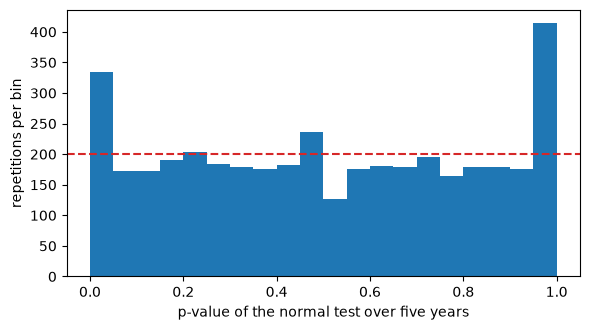

In [5]:
# Compare the simulated size of the normal test over five years with the tail of a t distribution
from riskvalidation.generators.counts import DefaultCounts, feed_series

row = rows["pd.normal_multiperiod@null"]
generator = DefaultCounts(**out["generators"][row["generator"]]["config"])
run = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed_series())
for alpha in (0.05, 0.01):
    measured = run.rates[f"p<{alpha:g}"]
    t_tail = stats.t.sf(stats.norm.isf(alpha), 4)
    print(f"level {alpha:.2f} | simulated size {measured.rate:.4f} | tail of t with 4 degrees of freedom {t_tail:.4f}")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(run.p_values, bins=20, range=(0, 1), color="tab:blue")
ax.axhline(len(run.p_values) / 20, color="tab:red", linestyle="--")
ax.set_xlabel("p-value of the normal test over five years")
ax.set_ylabel("repetitions per bin")
fig.tight_layout()
plt.show()

The simulated size is 0.0838 at 5% against a t tail of 0.0877, and 0.0405 at 1% against 0.0403: the heavy tail of four degrees of freedom accounts for the excess. The p-value histogram has no flat floor but a tall first bin, the signature of a threshold that is too optimistic. The paper describes the test as conservative; with independent years and a PD applied that is exactly right, this experiment shows it is anti-conservative, and by about a factor of two at 1%.

### Step 4: ties in the traffic lights and the Jeffreys test at 1%

The traffic-lights test colours each year by its standardised default rate and rejects when the colour profile is bad enough. A year with exactly the expected number of defaults lies on a colour boundary, and the engine offers two rules for it, `lower` and `upper`. The traffic-lights test has an exact rejection probability, which `traffic_lights_rejection_probability` returns for independent years. For the count tests, `critical_count` and `rejection_probability` give the Jeffreys test its size at 1%. The next cell prints both.

In [6]:
# Exact size of the traffic-lights test under the two rules for a tie, and of the Jeffreys test at 1%
from riskvalidation.harness.exact import critical_count, rejection_probability, traffic_lights_rejection_probability

for ties in ("lower", "upper"):
    for alpha in (0.05, 0.01):
        exact = traffic_lights_rejection_probability([1000] * 5, 0.03, alpha, pd_true=0.03, ties=ties)["probability"]
        print(f"traffic lights, ties={ties:5s} | level {alpha:.2f} | exact size {exact:.4f}")
for test in ("pd.binomial", "pd.jeffreys"):
    k_star = critical_count(test, 1000, 0.01, 0.01)
    size = rejection_probability(test, 1000, 0.01, 0.01)["probability"]
    print(f"{test:12s} | 1% | critical count {k_star} | exact size {size:.5f}")

traffic lights, ties=lower | level 0.05 | exact size 0.0379
traffic lights, ties=lower | level 0.01 | exact size 0.0074
traffic lights, ties=upper | level 0.05 | exact size 0.0603
traffic lights, ties=upper | level 0.01 | exact size 0.0113
pd.binomial  | 1% | critical count 19 | exact size 0.00690
pd.jeffreys  | 1% | critical count 18 | exact size 0.01383


The tie rule moves the traffic-lights test across its nominal level: with `lower` the exact size is 0.0379 at 5% and 0.0074 at 1%, below the level, and with `upper` it is 0.0603 and 0.0113, above it. The test is neither right nor wrong until the rule is stated. The Jeffreys test needs 18 defaults to reject at 1% where the binomial test needs 19, and its exact size is 0.01383 against 0.00690 for the binomial test: one more default in the rejection region pushes the Jeffreys test above its level.

### Step 5: is the Jeffreys excess a feature of one portfolio?

The previous step used one portfolio of 1,000 obligors at a PD of 1%. A discrete test can sit above its level at one PD and below it at the next, so the verdict of a single point is weak. Because the exact size needs no simulation, the next cell computes it for both count tests across PDs from 0.2% to 5% on the same 1,000 obligors, prints the largest and smallest exact size, and draws the two curves against the nominal 1%.

pd.binomial  | largest exact size at 1% 0.00974 | smallest 0.00374
pd.jeffreys  | largest exact size at 1% 0.01646 | smallest 0.00798


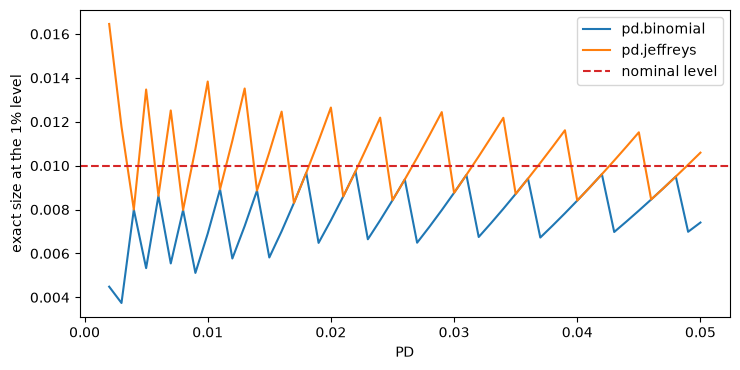

In [7]:
# Draw the exact size of both count tests against the PD of a 1000-obligor portfolio
pds = np.linspace(0.002, 0.05, 49)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for test, color in (("pd.binomial", "tab:blue"), ("pd.jeffreys", "tab:orange")):
    sizes = [rejection_probability(test, 1000, pd, 0.01)["probability"] for pd in pds]
    ax.plot(pds, sizes, color=color, label=test)
    print(f"{test:12s} | largest exact size at 1% {max(sizes):.5f} | smallest {min(sizes):.5f}")
ax.axhline(0.01, color="tab:red", linestyle="--", label="nominal level")
ax.set_xlabel("PD")
ax.set_ylabel("exact size at the 1% level")
ax.legend()
fig.tight_layout()
plt.show()

Both curves saw-tooth because the critical count jumps by whole defaults. The binomial test never exceeds its level on this range, with a largest exact size of 0.00974, and sits as low as 0.00374. The Jeffreys test reaches 0.01646 and drops to 0.00798, so it crosses the nominal 1% line repeatedly. The excess of the previous step is thus not a single unlucky portfolio but the behaviour of the test: it rejects one default earlier than the binomial test, and at the 1% level that costs a size above the level in part of the range.

### Step 6: a descriptive metric when the model is right

Not every output of the engine is a test. The AUC is an estimate, and a validator reads it with its own performance measures: bias, empirical standard error, the engine's model standard error and the coverage of its 95% interval. The next cell draws 400 datasets from the binormal generator of the study with 150 defaulters, computes `auc_with_variance` on each, passes the estimates and the model errors to `estimator_performance` and draws the estimates around the true AUC.

true AUC: 0.80193 | draws: 400
bias: -0.00038 | empirical error: 0.0188
model error relative to the empirical one, %: -4.57
coverage of the 95% interval: 0.935


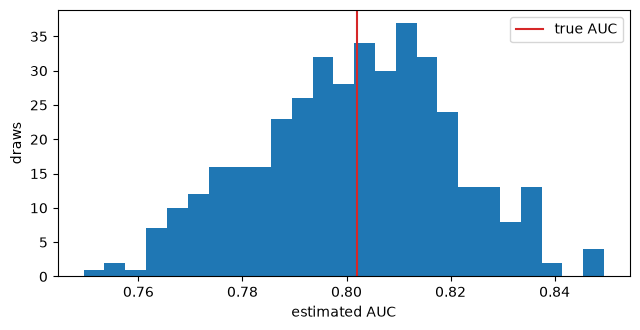

In [8]:
# Measure the AUC as an estimator on 400 fresh draws: bias, model error and coverage
from riskvalidation.generators.scores import BinormalScores
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.validation.discrimination import auc_with_variance

binormal = BinormalScores(**out["generators"]["binormal-150"]["config"])
estimates, model_se = [], []
for child in np.random.SeedSequence(11).spawn(400):
    sample = binormal.draw(np.random.default_rng(child))
    auc_hat, variance, _, _ = auc_with_variance(sample["risk"], sample["defaults"])
    estimates.append(auc_hat)
    model_se.append(np.sqrt(variance))
estimates, model_se = np.array(estimates), np.array(model_se)
truth = binormal.truth()["auc_current"]
lower, upper = estimates - 1.96 * model_se, estimates + 1.96 * model_se
perf = estimator_performance(estimates, truth, model_se=model_se, lower=lower, upper=upper)
print("true AUC:", round(truth, 5), "| draws:", perf["n"])
print("bias:", round(perf["bias"], 5), "| empirical error:", round(perf["empirical_se"], 5))
print("model error relative to the empirical one, %:", round(perf["model_se_relative_error_pct"], 2))
print("coverage of the 95% interval:", round(perf["coverage"], 4))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(estimates, bins=25, color="tab:blue")
ax.axvline(truth, color="tab:red", label="true AUC")
ax.set_xlabel("estimated AUC")
ax.set_ylabel("draws")
ax.legend()
fig.tight_layout()
plt.show()

The true AUC of the generator is 0.80193 and the estimates centre on it: the bias is -0.00038, far below the empirical error of 0.0188. The model error is 4.57% below the empirical one, so the interval is a little narrow, and the coverage of the nominal 95% interval is 0.935. With 400 draws the Monte Carlo error of a coverage near 0.95 is about one point, so the shortfall is mild but visible. An estimator can be unbiased and still report an interval slightly tighter than it deserves.

## Results

**Answer:** Four of the 46 null rows reject a right model more than their level allows, so 42 hold their size at both levels. The clearest offender is the normal test over five years, with sizes of 0.0838 at 5% and 0.0405 at 1%, which the tail of a t distribution with four degrees of freedom explains (0.0877 and 0.0403). Hosmer-Lemeshow with $G-2$ degrees of freedom rejects 0.1150 of the time at 5% against 0.0475 with the reference for given PDs, and the Jeffreys test has an exact size of 0.01383 at 1%.

- **The cause is in the construction.** A reference distribution that does not match the setting (Hosmer-Lemeshow), a spread estimated from five points (the normal test), a discrete critical count (the Jeffreys test) and a tie rule (the traffic lights, 0.0379 with `lower` and 0.0603 with `upper` at 5%) each explain one size, and each can be reproduced in a few lines of the engine.
- **Exact beats simulated.** For the count tests and the traffic lights the exact size settles the verdict with no Monte Carlo error; the Jeffreys test ranges from 0.00798 to 0.01646 at 1% across PDs, while the binomial test stays at or below 0.00974.
- **Estimators are not tests.** The AUC has a bias of -0.00038 but its interval covers 0.935 of the time, not 0.95.

What this notebook does not do is measure power; that is the work of notebook 03.

## Summary

- A test holds its size when its exact rejection probability, or its simulated rate against the one-sided bound, is at most the level at 5% and at 1%.
- Of the 46 null rows of the study, 42 hold their size; the offenders are the Jeffreys test, the normal test over five years and two Christoffersen tests.
- Each offender traces to its construction: the wrong reference distribution, a spread estimated from five points, a discrete critical count, or an unstated tie rule.
- The exact size of a count test needs no simulation and shows the saw-tooth that a single portfolio hides.
- The AUC is an estimator and is read with its bias, model error and interval coverage.

**What to try next.** Rerun step 3 with ten years instead of five and see the size approach the nominal level, then read notebook 03.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the normal test over several periods, the traffic-lights test and the chi-square test over grades. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 to 2.5.5 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.